# Session 5a: evaluating models (bias, variance and learning curves)

**Course link:** Machine Learning Specialization, Course 2 Week 3, Parts A–B (training / cross-validation / test sets, model selection, bias and variance, baseline level of performance, learning curves).

**Question:** Sessions 3 and 4 never beat the simple guess. Is that because the models are too simple (high bias), too flexible for so little data (high variance), or because the inputs hold almost no information about what comes next? And would more data help?

**Choices made before fitting anything:**
- Same rows, inputs and targets as Sessions 3–4: the 96 consolidation episodes; ΔCAPB and the four lagged controls; inflation capped at ±30 %; "weak" = TFP growth from t−1 to t+2 below the median of the training countries (original), or below the median of the training countries in the same year (year-adjusted).
- One model family from Course 1 and ML03b: logistic regression on polynomial features of the five inputs, degree 1, 2 or 3, z-scored on the training countries only, with λ from 0.01 to 1000.
- J_train and J_cv are log loss **without** the λ term, as in the course. The simple guess (the training share of "weak") is the baseline level of performance.
- Cross-validation: the 20 training countries in 4 groups, as in Session 4.
- The model with the lowest J_cv is then run once through the usual three tests: the six hidden countries, every country hidden in turn, and 500 random splits.

Runtime: about 45 minutes on a laptop, almost all of it the two placebo tests (sections 6 and 8). Everything before section 6 runs in about a minute.

In [1]:
# Load the panel straight from the GitHub repo (no upload needed)
DATA_URL = "https://raw.githubusercontent.com/penelopemichou/austerity-ml/main/data/panel_master.csv"

My predictions (fill these in before running; to hide the saved results first, use Edit → Clear all outputs)

1. In this project, which countries play the role of the training set, the cross-validation set and the test set?
2. As λ goes up, will J_train go up or down? And J_cv?
3. Degree 3 gives 55 features for about 50 training episodes per fold. Will its J_train be far below the simple guess? Its J_cv?
4. Which degree and λ will cross-validation pick?
5. Learning curves: with more training countries, will J_cv fall below the simple guess?
6. Diagnosis: high bias, high variance, or something else? Would more data help?
7. After Sessions 1–4, are the six hidden countries still a clean test set?
8. Section 6 shuffles which years count as consolidations (a placebo). Will the degree-2 model do better with the real episodes than with the shuffled ones?
9. Will the answer change when the degree and λ are chosen again inside every round?
10. Section 7 uses the log of trade openness for every country. Will Luxembourg's round still go badly wrong? Will the model then beat the simple guess with every country hidden in turn?
11. Section 8 repeats the placebo on the log version. Will the real episodes stand out this time?

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.exceptions import ConvergenceWarning
import warnings
warnings.filterwarnings("ignore", category=ConvergenceWarning)   # very small λ with degree 3 converges slowly

pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", None)
df = pd.read_csv(DATA_URL)

COUNTRY, YEAR, DCAPB, TFP = "country", "year", "dcapb_main", "tfp"
H, CAP = 2, 30
CONTROLS_RAW = ["gdp_growth", "debt_gdp", "inflation", "trade_open"]
CONTROLS = [c + "_lag1" for c in CONTROLS_RAW]
INPUTS = [DCAPB] + CONTROLS

def add_columns(frame, cap=CAP):
    d = frame.sort_values([COUNTRY, YEAR]).copy()
    d["inflation"] = d["inflation"].clip(-cap, cap)
    d["log_tfp"] = np.log(d[TFP])
    d["growth"] = 100 * (d.groupby(COUNTRY)["log_tfp"].shift(-H) - d.groupby(COUNTRY)["log_tfp"].shift(1))
    for raw, lagged in zip(CONTROLS_RAW, CONTROLS):
        d[lagged] = d.groupby(COUNTRY)[raw].shift(1)
    return d[[COUNTRY, YEAR, DCAPB, "growth"] + CONTROLS].dropna().reset_index(drop=True)

rows = add_columns(df)

def make_split(hidden, frame=rows, by_year=False):
    # "weak" is defined with cut-offs from the training countries only (per year when by_year=True)
    tr_all = frame[~frame[COUNTRY].isin(hidden)]
    median = tr_all.groupby(YEAR)["growth"].median() if by_year else tr_all["growth"].median()
    tr = tr_all[tr_all[DCAPB] >= 1.5].copy()
    te = frame[frame[COUNTRY].isin(hidden) & (frame[DCAPB] >= 1.5)].copy()
    for d in (tr, te):
        d["weak"] = (d["growth"] < (d[YEAR].map(median) if by_year else median)).astype(float)
    return tr, te

TEST_COUNTRIES = ["Belgium", "Greece", "Lithuania", "Malta", "Slovakia", "Spain"]   # same six as Sessions 1-4 (seed 42)
TARGETS = {"Original": False, "Year-adjusted": True}
episodes, _ = make_split([])
print(f"{len(episodes)} episodes in {episodes[COUNTRY].nunique()} countries")

96 episodes in 24 countries


## 1. Training, cross-validation and test sets in this project

**Course link:** Week 3, *Model selection and training / cross-validation / test sets*.

- **Training set:** the countries a model learns from.
- **Cross-validation set:** countries held back to *choose* between models (the degree, λ). In Sessions 3–4 these were the left-out training countries inside the tuning loop.
- **Test set:** countries held back to *report* how well the chosen model does. It should be touched once, at the end. Using it to choose anything makes the result look better than it is.

Our test set has been the same six hidden countries since Session 1, and their results were read in every session. Nothing was tuned on them on purpose (apart from the Session 3 leak, since fixed), but a person looking at the same six countries again and again is a mild form of choosing on the test set. That is why "every country hidden in turn" and the 500 random splits matter more than the six-country number.

In [3]:
train_countries = sorted(c for c in rows[COUNTRY].unique() if c not in TEST_COUNTRIES)

def cv_groups(countries, k=4):
    c = sorted(countries)
    np.random.default_rng(0).shuffle(c)
    return [c[i::k] for i in range(k)]

groups = cv_groups(train_countries)
tr, te = make_split(TEST_COUNTRIES)
print("Test set (six hidden countries):", ", ".join(TEST_COUNTRIES), f"-> {len(te)} episodes")
for i, g in enumerate(groups, 1):
    print(f"Cross-validation group {i}:", ", ".join(g), f"-> {int(tr[COUNTRY].isin(g).sum())} episodes")
print(f"Each fold trains on 3 groups (about {round(len(tr) * 3 / 4)} episodes) and scores the 4th.")

Test set (six hidden countries): Belgium, Greece, Lithuania, Malta, Slovakia, Spain -> 25 episodes
Cross-validation group 1: Denmark, Luxembourg, Ireland, France, Netherlands -> 15 episodes
Cross-validation group 2: Sweden, Portugal, Germany, Estonia, Hungary -> 19 episodes
Cross-validation group 3: Finland, Cyprus, Austria, Slovenia, Bulgaria -> 20 episodes
Cross-validation group 4: Croatia, Italy, Latvia, Romania, Poland -> 17 episodes
Each fold trains on 3 groups (about 53 episodes) and scores the 4th.


## 2. The model: logistic regression on polynomial features

Degree 1 is the Session 3 model. Degree 2 adds squares and products of the inputs (20 features), and degree 3 adds cubes and three-way products (55 features), the same idea as `poly_features` in ML03b but with all five inputs. More features means a more flexible boundary, and with about 50 training episodes per fold, a much easier time fitting noise.

The steps are the ones from earlier sessions: z-score the inputs on the training countries, build the polynomial features, z-score those again on the training countries, then fit with C = 1/λ.

In [4]:
DEGREES = [1, 2, 3]
LAMBDAS = [0.01, 0.1, 1, 3, 10, 30, 100, 300, 1000]

def log_loss(p, y):
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

def features(tr, te, degree):
    mu, sd = tr[INPUTS].mean(), tr[INPUTS].std(ddof=0).replace(0, 1)   # a constant column is left unscaled
    poly = PolynomialFeatures(degree, include_bias=False)
    F_tr = poly.fit_transform((tr[INPUTS] - mu) / sd)
    F_te = poly.transform((te[INPUTS] - mu) / sd)
    m, s = F_tr.mean(axis=0), F_tr.std(axis=0)
    s[s == 0] = 1
    return (F_tr - m) / s, (F_te - m) / s

def fit_predict(tr, te, degree, lam):
    F_tr, F_te = features(tr, te, degree)
    model = LogisticRegression(C=1 / lam, max_iter=20000).fit(F_tr, tr["weak"])
    return model.predict_proba(F_tr)[:, 1], model.predict_proba(F_te)[:, 1]

print("Features per degree:", {d: PolynomialFeatures(d, include_bias=False).fit(np.zeros((1, 5))).n_output_features_ for d in DEGREES})

Features per degree: {1: 5, 2: 20, 3: 55}


## 3. Model selection: J_train and J_cv for every degree and λ

**Course link:** Week 3, *Diagnosing bias and variance* and *Regularization and bias/variance*.

For each degree and λ: train on 3 groups, compute J_train on those training episodes and J_cv on the 4th group, and repeat so each group is used once. J_cv pools all four left-out groups. The simple guess is scored the same way.

In [5]:
def cross_validate(degree, lam, hidden=TEST_COUNTRIES, by_year=False, frame=rows):
    train_c = [c for c in frame[COUNTRY].unique() if c not in hidden]
    j_train, ys, ps, guesses, guess_train = [], [], [], [], []
    for g in cv_groups(train_c):
        tr, cv = make_split(list(hidden) + g, frame, by_year)
        cv = cv[cv[COUNTRY].isin(g)]                      # score only the left-out training countries
        p_tr, p_cv = fit_predict(tr, cv, degree, lam)
        prior = tr["weak"].mean()
        j_train.append(log_loss(p_tr, tr["weak"].to_numpy()))
        guess_train.append(log_loss(np.full(len(tr), prior), tr["weak"].to_numpy()))
        ys.append(cv["weak"].to_numpy()); ps.append(p_cv); guesses.append(np.full(len(cv), prior))
    y = np.concatenate(ys)
    return {"J_train": np.mean(j_train), "J_cv": log_loss(np.concatenate(ps), y),
            "guess J_train": np.mean(guess_train), "guess J_cv": log_loss(np.concatenate(guesses), y)}

grid = pd.DataFrame([{"target": t, "degree": d, "λ": l, **cross_validate(d, l, by_year=b)}
                     for t, b in TARGETS.items() for d in DEGREES for l in LAMBDAS]).set_index(["target", "degree", "λ"])
best = {t: grid.loc[t]["J_cv"].idxmin() for t in TARGETS}
for t in TARGETS:
    print(f"{t}: lowest J_cv = {grid.loc[t]['J_cv'].min():.3f} at degree {best[t][0]}, λ = {best[t][1]:g}; "
          f"simple guess J_cv = {grid.loc[t]['guess J_cv'].iloc[0]:.3f}")
grid.round(3).unstack("degree")[["J_train", "J_cv"]]

Original: lowest J_cv = 0.680 at degree 2, λ = 100; simple guess J_cv = 0.698
Year-adjusted: lowest J_cv = 0.643 at degree 2, λ = 30; simple guess J_cv = 0.696


J_train                 J_cv              
degree                      1      2      3      1      2      3
target        λ                                                 
Original      0.01      0.617  0.338  0.116  0.877  2.486  2.881
              0.10      0.617  0.386  0.243  0.869  1.687  1.647
              1.00      0.619  0.459  0.372  0.823  1.077  1.201
              3.00      0.625  0.505  0.433  0.780  0.904  1.001
              10.00     0.640  0.560  0.504  0.732  0.760  0.787
              30.00     0.659  0.607  0.565  0.706  0.696  0.682
              100.00    0.676  0.649  0.618  0.698  0.680  0.702
              300.00    0.684  0.671  0.653  0.698  0.688  0.700
              1000.00   0.687  0.683  0.675  0.698  0.694  0.697
Year-adjusted 0.01      0.629  0.379  0.125  0.901  2.047  2.887
              0.10      0.629  0.424  0.251  0.895  1.490  1.881
              1.00      0.631  0.482  0.377  0.860  0.898  1.365
              3.00      0.635  0.517  0.437  0.821  0.731  1.145
              10.00     0.646  0.563  0.504  0.764  0.660  0.926
              30.00     0.663  0.608  0.564  0.722  0.643  0.763
              100.00    0.678  0.649  0.619  0.703  0.658  0.750
              300.00    0.685  0.672  0.654  0.698  0.679  0.719
              1000.00   0.688  0.684  0.676  0.697  0.690  0.701

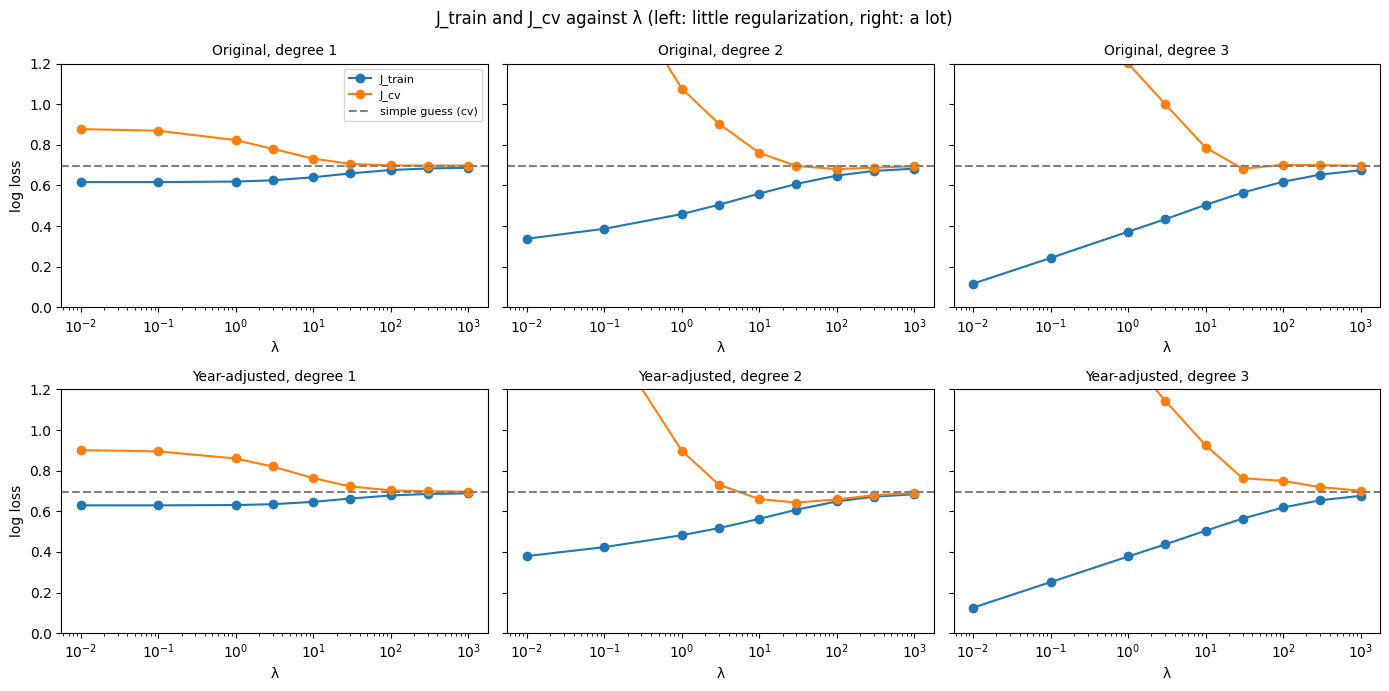

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharey=True)
for r, t in enumerate(TARGETS):
    g = grid.loc[t]
    for c, d in enumerate(DEGREES):
        ax = axes[r, c]
        ax.plot(LAMBDAS, g.loc[d]["J_train"], "o-", label="J_train")
        ax.plot(LAMBDAS, g.loc[d]["J_cv"], "o-", label="J_cv")
        ax.axhline(g["guess J_cv"].iloc[0], ls="--", color="grey", label="simple guess (cv)")
        ax.set_xscale("log"); ax.set_ylim(0, 1.2)
        ax.set_title(f"{t}, degree {d}", fontsize=10); ax.set_xlabel("λ")
        if c == 0: ax.set_ylabel("log loss")
axes[0, 0].legend(fontsize=8)
plt.suptitle("J_train and J_cv against λ (left: little regularization, right: a lot)")
plt.tight_layout(); plt.show()

**How to read it (the course rules):** if J_train is far above the baseline level, the model has *high bias*; if J_cv is far above J_train, it has *high variance*. Here the baseline level is the simple guess: no model is known to do better on this question.

## 4. Learning curves: would more countries help?

**Course link:** Week 3, *Learning curves*.

Inside the 20 training countries, 4 countries are held back as a cross-validation set, and the model is trained on 2, 4, …, 16 of the others. This is repeated 200 times with different random countries, and J_train and J_cv are averaged. The "weak" cut-offs come from the countries the model is trained on, as always. Two models are compared: the one cross-validation picked in section 3, and a flexible one (degree 3, λ = 0.1).

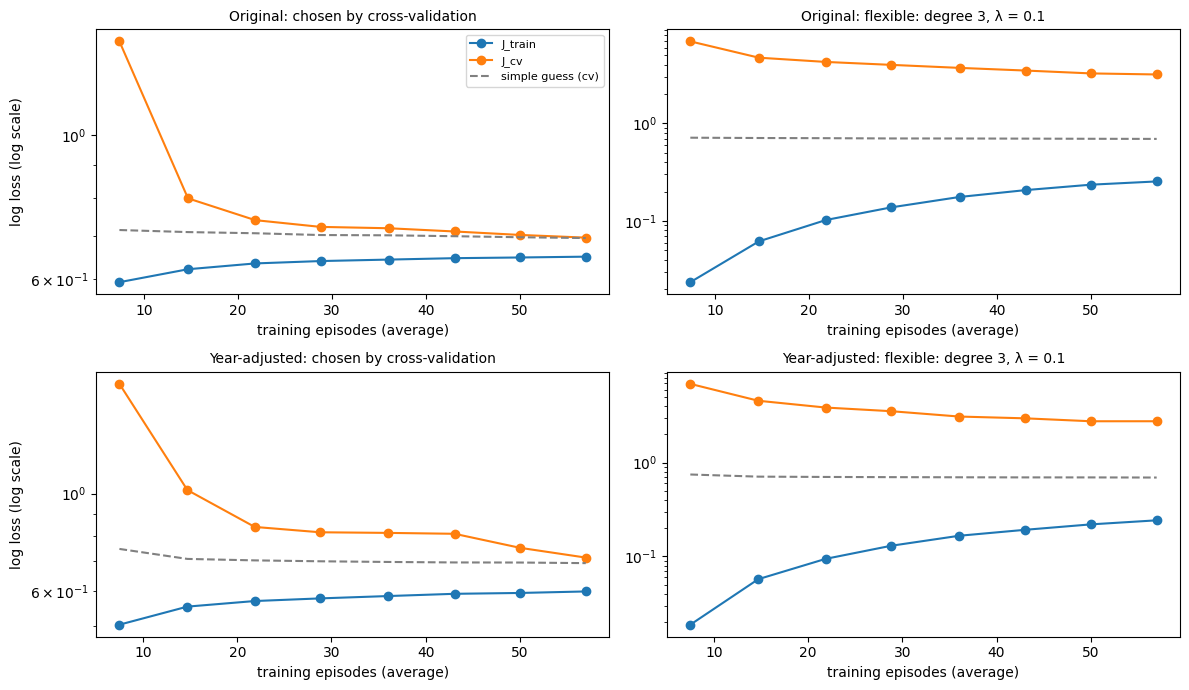

('Original', 'chosen by cross-validation') | at 16 countries: {'episodes': 57.015, 'J_train': 0.65, 'J_cv': 0.695, 'guess': 0.694}
('Original', 'flexible: degree 3, λ = 0.1') | at 16 countries: {'episodes': 57.015, 'J_train': 0.255, 'J_cv': 3.176, 'guess': 0.694}
('Year-adjusted', 'chosen by cross-validation') | at 16 countries: {'episodes': 57.015, 'J_train': 0.598, 'J_cv': 0.714, 'guess': 0.694}
('Year-adjusted', 'flexible: degree 3, λ = 0.1') | at 16 countries: {'episodes': 57.015, 'J_train': 0.243, 'J_cv': 2.762, 'guess': 0.694}


In [7]:
SIZES = [2, 4, 6, 8, 10, 12, 14, 16]

def learning_curve(degree, lam, by_year, repeats=200):
    rng = np.random.default_rng(1)
    out = {n: {"J_train": [], "J_cv": [], "guess": [], "episodes": []} for n in SIZES}
    for _ in range(repeats):
        order = list(rng.permutation(train_countries))
        cv_c, pool = order[:4], order[4:]
        for n in SIZES:
            used = pool[:n]
            hidden = [c for c in rows[COUNTRY].unique() if c not in used]   # everything not used for training
            tr, rest = make_split(hidden, by_year=by_year)
            cv = rest[rest[COUNTRY].isin(cv_c)]
            if tr["weak"].nunique() < 2 or len(cv) == 0:
                continue
            p_tr, p_cv = fit_predict(tr, cv, degree, lam)
            prior = tr["weak"].mean()
            out[n]["J_train"].append(log_loss(p_tr, tr["weak"].to_numpy()))
            out[n]["J_cv"].append(log_loss(p_cv, cv["weak"].to_numpy()))
            out[n]["guess"].append(log_loss(np.full(len(cv), prior), cv["weak"].to_numpy()))
            out[n]["episodes"].append(len(tr))
    return pd.DataFrame({n: {k: np.mean(v) for k, v in d.items()} for n, d in out.items()}).T.rename_axis("training countries")

curves = {(t, name): learning_curve(d, l, b)
          for t, b in TARGETS.items()
          for name, (d, l) in {"chosen by cross-validation": best[t], "flexible: degree 3, λ = 0.1": (3, 0.1)}.items()}

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, ((t, name), lc) in zip(axes.ravel(), curves.items()):
    ax.plot(lc["episodes"], lc["J_train"], "o-", label="J_train")
    ax.plot(lc["episodes"], lc["J_cv"], "o-", label="J_cv")
    ax.plot(lc["episodes"], lc["guess"], "--", color="grey", label="simple guess (cv)")
    ax.set_title(f"{t}: {name}", fontsize=10); ax.set_xlabel("training episodes (average)"); ax.set_yscale("log")
axes[0, 0].set_ylabel("log loss (log scale)"); axes[1, 0].set_ylabel("log loss (log scale)"); axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()
for key, lc in curves.items():
    print(key, "| at 16 countries:", lc.iloc[-1][["episodes", "J_train", "J_cv", "guess"]].round(3).to_dict())

## 5. The test set, once: the three tests for the model cross-validation picked

The model chosen in section 3 now goes through the usual tests. With every country hidden in turn, the degree and λ are chosen again by cross-validation inside each round. The 500 random splits keep the section 3 choice (slightly optimistic, as before).

In [8]:
def choose(hidden, by_year):
    scores = {(d, l): cross_validate(d, l, hidden, by_year)["J_cv"] for d in DEGREES for l in LAMBDAS}
    return min(scores, key=scores.get)

def scores(y, p, prior):
    return {"log loss": log_loss(p, y), "baseline log loss": log_loss(np.full(len(y), prior), y),
            "accuracy": np.mean((p >= 0.5) == y), "baseline accuracy": np.mean(float(prior >= 0.5) == y)}

final, worst = {}, {}
for t, b in TARGETS.items():
    d, l = best[t]
    tr, te = make_split(TEST_COUNTRIES, by_year=b)
    six = scores(te["weak"].to_numpy(), fit_predict(tr, te, d, l)[1], tr["weak"].mean())
    ys, ps, gs, per = [], [], [], []
    for c in rows.loc[rows[DCAPB] >= 1.5, COUNTRY].unique():
        dc, lc = choose([c], b)
        tr_c, te_c = make_split([c], by_year=b)
        p, y, prior = fit_predict(tr_c, te_c, dc, lc)[1], te_c["weak"].to_numpy(), tr_c["weak"].mean()
        ys.append(y); ps.append(p); gs.append(np.full(len(y), prior))
        per.append({"country": c, "episodes": len(y), "chosen": (dc, lc), "log loss": log_loss(p, y),
                    "baseline": log_loss(np.full(len(y), prior), y), "won": log_loss(p, y) < log_loss(np.full(len(y), prior), y)})
    y, p, g = map(np.concatenate, (ys, ps, gs))
    rng = np.random.default_rng(0)
    countries = rows.loc[rows[DCAPB] >= 1.5, COUNTRY].unique()
    gains = []
    for _ in range(500):
        tr_r, te_r = make_split(rng.choice(countries, size=6, replace=False), by_year=b)
        s = scores(te_r["weak"].to_numpy(), fit_predict(tr_r, te_r, d, l)[1], tr_r["weak"].mean())
        gains.append(100 * (1 - s["log loss"] / s["baseline log loss"]))
    per = pd.DataFrame(per)
    per["effect on overall (points)"] = -100 * per["episodes"] * (per["log loss"] - per["baseline"]) / (len(y) * log_loss(g, y))
    worst[t] = per.sort_values("effect on overall (points)").head(3).set_index("country")
    final[t] = {"chosen (degree, λ)": f"({d}, {l:g})",
                "six hidden: log loss vs baseline": f"{six['log loss']:.3f} vs {six['baseline log loss']:.3f}",
                "six hidden: accuracy vs baseline": f"{six['accuracy']:.0%} vs {six['baseline accuracy']:.0%}",
                "each hidden in turn: log loss vs baseline": f"{log_loss(p, y):.3f} vs {log_loss(g, y):.3f} ({100 * (1 - log_loss(p, y) / log_loss(g, y)):+.1f} %)",
                "each hidden in turn: accuracy vs baseline": f"{np.mean((p >= 0.5) == y):.1%} vs {np.mean((g >= 0.5) == y):.1%}",
                "countries won": f"{int(per['won'].sum())} of {len(per)}",
                "settings chosen across the 24 rounds": ", ".join(f"{k} ×{v}" for k, v in per["chosen"].value_counts().items()),
                "500 splits: log loss better": f"{np.mean(np.array(gains) > 0):.0%} (median {np.median(gains):+.1f} %)"}
pd.DataFrame(final)

,Original,Year-adjusted
"chosen (degree, λ)","(2, 100)","(2, 30)"
six hidden: log loss vs baseline,0.667 vs 0.710,0.624 vs 0.718
six hidden: accuracy vs baseline,52% vs 40%,52% vs 40%
each hidden in turn: log loss vs baseline,0.919 vs 0.694 (-32.4 %),0.704 vs 0.700 (-0.6 %)
each hidden in turn: accuracy vs baseline,58.3% vs 49.0%,60.4% vs 42.7%
countries won,15 of 24,14 of 24
settings chosen across the 24 rounds,"(2, 30) ×13, (2, 10) ×8, (1, 300) ×1, (2, 100) ×1, (3, 10) ×1","(2, 30) ×11, (2, 10) ×5, (2, 100) ×5, (2, 300) ×1, (1, 10) ×1, (1, 300) ×1"
500 splits: log loss better,77% (median +2.9 %),69% (median +3.5 %)


In [9]:
# Which rounds pull the "each hidden in turn" result down the most? (as in Session 4)
for t, w in worst.items():
    print(t); print(w[["episodes", "chosen", "log loss", "baseline", "effect on overall (points)"]].round(3).to_string()); print()

Original
            episodes   chosen  log loss  baseline  effect on overall (points)
country                                                                      
Luxembourg         5  (3, 10)     5.908     0.674                     -39.283
Hungary            6  (2, 30)     0.781     0.693                      -0.793
Estonia            3  (2, 30)     0.774     0.690                      -0.381

Year-adjusted
            episodes   chosen  log loss  baseline  effect on overall (points)
country                                                                      
Luxembourg         5  (1, 10)     1.313     0.691                      -4.632
Hungary            6  (2, 30)     0.807     0.701                      -0.948
Spain              2  (2, 30)     0.856     0.693                      -0.486



## 6. Placebo test: does the degree-2 gain depend on the real consolidation years?

As in Session 3: within each country, the ΔCAPB values are shuffled across years, so each country keeps its number of episodes and their sizes but *which years* count as consolidations becomes random. The model is rerun on each shuffled panel with every country hidden in turn. If the real episodes do no better than the shuffled ones, the small gain is not about consolidations.

Two versions:
- **Fast:** 500 shuffles, with the degree and λ fixed at the section 3 choice (degree 2; λ = 100 original, 30 year-adjusted). Like the Session 3 placebo, it is slightly optimistic and may slightly favour the real episodes, because those settings were chosen on the real data.
- **Clean:** 100 shuffles, with the degree and λ chosen again by cross-validation inside every round, exactly like section 5. Nothing is tuned on the real episodes, so there is no such caveat. It takes several minutes; the shuffles run in parallel on all processor cores.

In [10]:
from joblib import Parallel, delayed

def shuffle_episodes(frame, seed):
    # Within each country, hand the ΔCAPB values to randomly chosen years
    rng = np.random.default_rng(seed)
    d = frame.copy()
    d[DCAPB] = d.groupby(COUNTRY)[DCAPB].transform(lambda s: rng.permutation(s.to_numpy()))
    return d

def loco_stats(frame, by_year, fixed=None):
    # Every country hidden in turn; settings fixed, or chosen again by cross-validation in each round
    ys, ps, gs, won = [], [], [], 0
    for c in frame.loc[frame[DCAPB] >= 1.5, COUNTRY].unique():
        tr, te = make_split([c], frame, by_year)
        if fixed is not None:
            d, l = fixed
        else:
            scores_ = {(dd, ll): cross_validate(dd, ll, [c], by_year, frame)["J_cv"] for dd in DEGREES for ll in LAMBDAS}
            d, l = min(scores_, key=scores_.get)
        p, y, g = fit_predict(tr, te, d, l)[1], te["weak"].to_numpy(), np.full(len(te), tr["weak"].mean())
        won += log_loss(p, y) < log_loss(g, y)
        ys.append(y); ps.append(p); gs.append(g)
    y, p, g = map(np.concatenate, (ys, ps, gs))
    return (100 * (1 - log_loss(p, y) / log_loss(g, y)),
            100 * (np.mean((p >= 0.5) == y) - np.mean((g >= 0.5) == y)), won)

example = shuffle_episodes(rows, 0)
print("Each country keeps its number of episodes:",
      example[example[DCAPB] >= 1.5].groupby(COUNTRY).size().sort_index().equals(rows[rows[DCAPB] >= 1.5].groupby(COUNTRY).size().sort_index()))

Each country keeps its number of episodes: True


In [11]:
# This cell takes several minutes (the clean version chooses the settings again in every round of every shuffle)
placebo = {}
for t, b in TARGETS.items():
    for version, fixed, n in [("fast (settings fixed)", best[t], 500), ("clean (settings chosen in every round)", None, 100)]:
        real = loco_stats(rows, b, fixed)
        fake = np.array(Parallel(n_jobs=-1)(delayed(loco_stats)(shuffle_episodes(rows, seed), b, fixed) for seed in range(n)))
        placebo[(t, version)] = (real, fake)

table = {}
for key, (real, fake) in placebo.items():
    table[key] = {
        "shuffles": len(fake),
        "real: log loss vs baseline (%)": f"{real[0]:+.1f}",
        "shuffled: median (middle 90 %)": f"{np.median(fake[:, 0]):+.1f} ({np.percentile(fake[:, 0], 5):+.1f} to {np.percentile(fake[:, 0], 95):+.1f})",
        "shuffles at least as good (log loss)": f"{np.mean(fake[:, 0] >= real[0]):.0%}",
        "real: accuracy minus baseline (points)": f"{real[1]:+.1f}",
        "shuffled accuracy: median (middle 90 %)": f"{np.median(fake[:, 1]):+.1f} ({np.percentile(fake[:, 1], 5):+.1f} to {np.percentile(fake[:, 1], 95):+.1f})",
        "shuffles at least as good (accuracy)": f"{np.mean(fake[:, 1] >= real[1]):.0%}",
        "countries won: real vs shuffled median": f"{real[2]} vs {np.median(fake[:, 2]):.0f} of 24"}
pd.DataFrame(table)

Original                                                Year-adjusted  \
                                        fast (settings fixed) clean (settings chosen in every round) fast (settings fixed)   
shuffles                                                  500                                    100                   500   
real: log loss vs baseline (%)                           +4.1                                  -32.4                  +5.6   
shuffled: median (middle 90 %)            +0.4 (-6.4 to +6.2)                   -6.5 (-40.0 to +5.2)  -3.5 (-19.5 to +7.9)   
shuffles at least as good (log loss)                      15%                                    94%                   10%   
real: accuracy minus baseline (points)                  +11.5                                   +9.4                 +16.7   
shuffled accuracy: median (middle 90 %)  +3.1 (-3.1 to +18.7)                   +1.0 (-4.2 to +18.8)  +5.2 (-2.1 to +18.8)   
shuffles at least as good (accuracy)                      12%                                     9%                    6%   
countries won: real vs shuffled median         16 vs 14 of 24                         15 vs 14 of 24        13 vs 14 of 24   

                                                                                
                                        clean (settings chosen in every round)  
shuffles                                                                   100  
real: log loss vs baseline (%)                                            -0.6  
shuffled: median (middle 90 %)                            -7.6 (-29.4 to +4.1)  
shuffles at least as good (log loss)                                       15%  
real: accuracy minus baseline (points)                                   +17.7  
shuffled accuracy: median (middle 90 %)                   +1.0 (-2.1 to +13.6)  
shuffles at least as good (accuracy)                                        2%  
countries won: real vs shuffled median                          14 vs 14 of 24

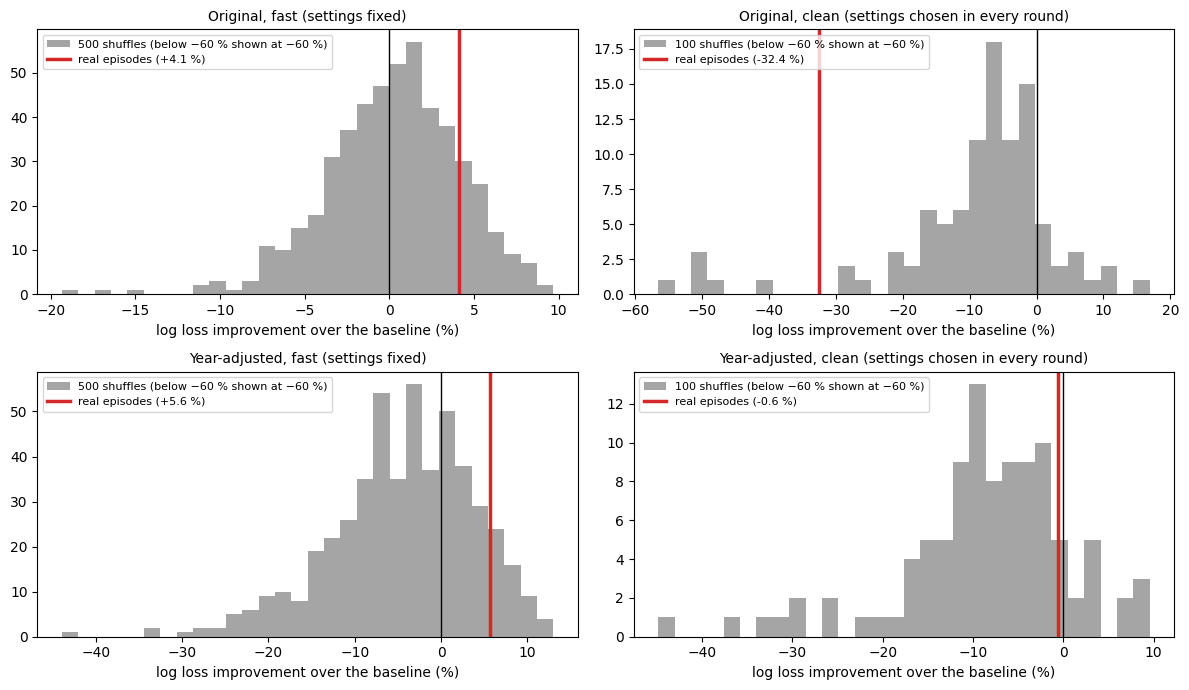

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, ((t, version), (real, fake)) in zip(axes.ravel(), placebo.items()):
    shown = np.clip(fake[:, 0], -60, None)
    ax.hist(shown, bins=30, color="tab:grey", alpha=0.7, label=f"{len(fake)} shuffles (below −60 % shown at −60 %)")
    ax.axvline(max(real[0], -60), color="tab:red", lw=2.5, label=f"real episodes ({real[0]:+.1f} %)")
    ax.axvline(0, color="black", lw=1)
    ax.set_title(f"{t}, {version}", fontsize=10); ax.set_xlabel("log loss improvement over the baseline (%)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 7. A rule for every country: the log of trade openness

Luxembourg's trade openness (240–376 % of GDP in its episodes) is far above every other country (the median episode is about 110 %). When Luxembourg is hidden, the model has to extrapolate, and squares or cubes of such a value give extreme predictions. Dropping Luxembourg would choose the sample by the result. Instead, one rule for all countries, **decided before running**: use the natural log of trade openness. The log squeezes large values together (log 400 is only about 1.3 more than log 110). Nothing else changes: the same degrees, λ values, cross-validation groups, targets and tests as sections 3 and 5. The result is reported whichever way it goes.

In [13]:
TRADE = "trade_open_lag1"
rows_log = rows.copy()
rows_log[TRADE] = np.log(rows_log[TRADE])

ep_raw, _ = make_split([])
ep_log, _ = make_split([], rows_log)
z = lambda s: (s - s.mean()) / s.std(ddof=0)
lux = ep_raw[COUNTRY] == "Luxembourg"
print("Luxembourg episodes, trade openness as a z-score among all episodes:")
print(pd.DataFrame({"year": ep_raw.loc[lux, YEAR].to_numpy(),
                    "% of GDP": ep_raw.loc[lux, TRADE].round(0).to_numpy(),
                    "z-score, raw": z(ep_raw[TRADE])[lux].round(1).to_numpy(),
                    "z-score, log": z(ep_log[TRADE])[lux].round(1).to_numpy()}).to_string(index=False))

Luxembourg episodes, trade openness as a z-score among all episodes:
 year  % of GDP  z-score, raw  z-score, log
 2000     240.0           1.9           1.7
 2005     265.0           2.3           1.9
 2011     294.0           2.7           2.1
 2018     354.0           3.7           2.5
 2021     376.0           4.0           2.7


In [14]:
def loco_detail(frame, by_year):
    # Every country hidden in turn, degree and λ chosen again by cross-validation in each round (as in section 5)
    rows_out, ys, ps, gs = [], [], [], []
    for c in frame.loc[frame[DCAPB] >= 1.5, COUNTRY].unique():
        scores_ = {(d, l): cross_validate(d, l, [c], by_year, frame)["J_cv"] for d in DEGREES for l in LAMBDAS}
        d, l = min(scores_, key=scores_.get)
        tr, te = make_split([c], frame, by_year)
        p, y, g = fit_predict(tr, te, d, l)[1], te["weak"].to_numpy(), np.full(len(te), tr["weak"].mean())
        ys.append(y); ps.append(p); gs.append(g)
        rows_out.append({"country": c, "episodes": len(y), "chosen": (d, l), "log loss": log_loss(p, y), "baseline": log_loss(g, y)})
    y, p, g = map(np.concatenate, (ys, ps, gs))
    per = pd.DataFrame(rows_out).set_index("country")
    per["effect on overall (points)"] = -100 * per["episodes"] * (per["log loss"] - per["baseline"]) / (len(y) * log_loss(g, y))
    pooled = {"log loss": log_loss(p, y), "baseline": log_loss(g, y), "gain %": 100 * (1 - log_loss(p, y) / log_loss(g, y)),
              "accuracy": np.mean((p >= 0.5) == y), "baseline accuracy": np.mean((g >= 0.5) == y),
              "won": int((per["log loss"] < per["baseline"]).sum())}
    return pooled, per

log_results, log_per, log_best = {}, {}, {}
for t, b in TARGETS.items():
    grid_t = {(d, l): cross_validate(d, l, TEST_COUNTRIES, b, rows_log) for d in DEGREES for l in LAMBDAS}
    d, l = min(grid_t, key=lambda k: grid_t[k]["J_cv"])
    log_best[t] = (d, l)
    tr, te = make_split(TEST_COUNTRIES, rows_log, b)
    six = scores(te["weak"].to_numpy(), fit_predict(tr, te, d, l)[1], tr["weak"].mean())
    pooled, per = loco_detail(rows_log, b)
    rng = np.random.default_rng(0)
    countries = rows_log.loc[rows_log[DCAPB] >= 1.5, COUNTRY].unique()
    gains = []
    for _ in range(500):
        tr_r, te_r = make_split(rng.choice(countries, size=6, replace=False), rows_log, b)
        s_ = scores(te_r["weak"].to_numpy(), fit_predict(tr_r, te_r, d, l)[1], tr_r["weak"].mean())
        gains.append(100 * (1 - s_["log loss"] / s_["baseline log loss"]))
    gains = np.array(gains)
    print(f"{t}, log trade openness: lowest J_cv {grid_t[(d, l)]['J_cv']:.3f} at degree {d}, λ = {l:g} (simple guess {grid_t[(d, l)]['guess J_cv']:.3f})")
    log_per[t] = per
    log_results[t] = {
        "chosen (degree, λ)": f"({d}, {l:g})",
        "six hidden: log loss vs baseline": f"{six['log loss']:.3f} vs {six['baseline log loss']:.3f}",
        "six hidden: accuracy vs baseline": f"{six['accuracy']:.0%} vs {six['baseline accuracy']:.0%}",
        "each hidden in turn: log loss vs baseline": f"{pooled['log loss']:.3f} vs {pooled['baseline']:.3f} ({pooled['gain %']:+.1f} %)",
        "each hidden in turn: accuracy vs baseline": f"{pooled['accuracy']:.1%} vs {pooled['baseline accuracy']:.1%}",
        "countries won": f"{pooled['won']} of {len(per)}",
        "settings chosen across the 24 rounds": ", ".join(f"{k} ×{v}" for k, v in per["chosen"].value_counts().items()),
        "500 splits: log loss better": f"{np.mean(gains > 0):.0%} (median {np.median(gains):+.1f} %)"}

comparison = {}
for t in TARGETS:
    comparison[(t, "raw trade openness (section 5)")] = final[t]
    comparison[(t, "log trade openness")] = log_results[t]
pd.DataFrame(comparison)

Original, log trade openness: lowest J_cv 0.674 at degree 2, λ = 30 (simple guess 0.698)


Year-adjusted, log trade openness: lowest J_cv 0.614 at degree 2, λ = 10 (simple guess 0.696)


Original                                                    \
                                                                          raw trade openness (section 5)                                log trade openness   
chosen (degree, λ)                                                                              (2, 100)                                           (2, 30)   
six hidden: log loss vs baseline                                                          0.667 vs 0.710                                    0.620 vs 0.710   
six hidden: accuracy vs baseline                                                              52% vs 40%                                        72% vs 40%   
each hidden in turn: log loss vs baseline                                       0.919 vs 0.694 (-32.4 %)                           0.682 vs 0.694 (+1.7 %)   
each hidden in turn: accuracy vs baseline                                                 58.3% vs 49.0%                                    62.5% vs 49.0%   
countries won                                                                                   15 of 24                                          16 of 24   
settings chosen across the 24 rounds       (2, 30) ×13, (2, 10) ×8, (1, 300) ×1, (2, 100) ×1, (3, 10) ×1  (2, 30) ×16, (2, 10) ×6, (1, 100) ×1, (3, 30) ×1   
500 splits: log loss better                                                          77% (median +2.9 %)                               84% (median +6.8 %)   

                                                                                                        Year-adjusted  \
                                                                                       raw trade openness (section 5)   
chosen (degree, λ)                                                                                            (2, 30)   
six hidden: log loss vs baseline                                                                       0.624 vs 0.718   
six hidden: accuracy vs baseline                                                                           52% vs 40%   
each hidden in turn: log loss vs baseline                                                     0.704 vs 0.700 (-0.6 %)   
each hidden in turn: accuracy vs baseline                                                              60.4% vs 42.7%   
countries won                                                                                                14 of 24   
settings chosen across the 24 rounds       (2, 30) ×11, (2, 10) ×5, (2, 100) ×5, (2, 300) ×1, (1, 10) ×1, (1, 300) ×1   
500 splits: log loss better                                                                       69% (median +3.5 %)   

                                                                                                                                   
                                                                                                               log trade openness  
chosen (degree, λ)                                                                                                        (2, 10)  
six hidden: log loss vs baseline                                                                                   0.594 vs 0.718  
six hidden: accuracy vs baseline                                                                                       60% vs 40%  
each hidden in turn: log loss vs baseline                                                                 0.686 vs 0.700 (+1.9 %)  
each hidden in turn: accuracy vs baseline                                                                          61.5% vs 42.7%  
countries won                                                                                                            13 of 24  
settings chosen across the 24 rounds       (2, 30) ×12, (2, 10) ×4, (2, 100) ×3, (1, 10) ×2, (3, 100) ×1, (3, 30) ×1, (1, 100) ×1  
500 splits: log loss better                                                                                   64% (m

In [15]:
for t, per in log_per.items():
    print(t, "- the three worst rounds, and Luxembourg:")
    show = pd.concat([per.sort_values("effect on overall (points)").head(3), per.loc[["Luxembourg"]]]).drop_duplicates()
    print(show[["episodes", "chosen", "log loss", "baseline", "effect on overall (points)"]].round(3).to_string()); print()

Original - the three worst rounds, and Luxembourg:
            episodes   chosen  log loss  baseline  effect on overall (points)
country                                                                      
Luxembourg         5  (3, 30)     1.554     0.674                      -6.610
Hungary            6  (2, 30)     0.792     0.693                      -0.890
Estonia            3  (2, 30)     0.778     0.690                      -0.397

Year-adjusted - the three worst rounds, and Luxembourg:
            episodes   chosen  log loss  baseline  effect on overall (points)
country                                                                      
Luxembourg         5  (1, 10)     1.093     0.691                      -2.992
Latvia             5  (1, 10)     0.902     0.700                      -1.505
Hungary            6  (2, 30)     0.827     0.701                      -1.131



## 8. Placebo test on the log version

The same two versions as section 6, now on the panel with the log of trade openness:
- **Fast:** 500 shuffles, settings fixed at the section 7 choice (slightly optimistic, may favour the real episodes).
- **Clean:** 100 shuffles, degree and λ chosen again by cross-validation inside every round (no such caveat).

If the small gain in section 7 is about consolidations, the real episodes should beat most shuffles. If it comes from the controls predicting TFP growth in general, the shuffled panels should do about as well.

In [16]:
# This cell takes several minutes
placebo_log = {}
for t, b in TARGETS.items():
    for version, fixed, n in [("fast (settings fixed)", log_best[t], 500), ("clean (settings chosen in every round)", None, 100)]:
        real = loco_stats(rows_log, b, fixed)
        fake = np.array(Parallel(n_jobs=-1)(delayed(loco_stats)(shuffle_episodes(rows_log, seed), b, fixed) for seed in range(n)))
        placebo_log[(t, version)] = (real, fake)

pd.DataFrame({key: {
    "shuffles": len(fake),
    "real: log loss vs baseline (%)": f"{real[0]:+.1f}",
    "shuffled: median (middle 90 %)": f"{np.median(fake[:, 0]):+.1f} ({np.percentile(fake[:, 0], 5):+.1f} to {np.percentile(fake[:, 0], 95):+.1f})",
    "shuffles at least as good (log loss)": f"{np.mean(fake[:, 0] >= real[0]):.0%}",
    "real: accuracy minus baseline (points)": f"{real[1]:+.1f}",
    "shuffled accuracy: median (middle 90 %)": f"{np.median(fake[:, 1]):+.1f} ({np.percentile(fake[:, 1], 5):+.1f} to {np.percentile(fake[:, 1], 95):+.1f})",
    "shuffles at least as good (accuracy)": f"{np.mean(fake[:, 1] >= real[1]):.0%}",
    "countries won: real vs shuffled median": f"{real[2]} vs {np.median(fake[:, 2]):.0f} of 24"}
    for key, (real, fake) in placebo_log.items()})

Original                                                Year-adjusted  \
                                        fast (settings fixed) clean (settings chosen in every round) fast (settings fixed)   
shuffles                                                  500                                    100                   500   
real: log loss vs baseline (%)                           +8.8                                   +1.7                  +7.8   
shuffled: median (middle 90 %)           -1.9 (-15.5 to +8.8)                   -3.8 (-20.8 to +6.2)  -7.1 (-33.9 to +8.3)   
shuffles at least as good (log loss)                       5%                                    16%                    6%   
real: accuracy minus baseline (points)                  +16.7                                  +13.5                 +19.8   
shuffled accuracy: median (middle 90 %)  +3.1 (-5.2 to +19.8)                   +3.1 (-4.2 to +17.8)  +5.2 (-3.2 to +18.7)   
shuffles at least as good (accuracy)                       8%                                     9%                    5%   
countries won: real vs shuffled median         16 vs 13 of 24                         16 vs 14 of 24        12 vs 13 of 24   

                                                                                
                                        clean (settings chosen in every round)  
shuffles                                                                   100  
real: log loss vs baseline (%)                                            +1.9  
shuffled: median (middle 90 %)                            -3.2 (-14.9 to +6.9)  
shuffles at least as good (log loss)                                       21%  
real: accuracy minus baseline (points)                                   +18.8  
shuffled accuracy: median (middle 90 %)                   +3.1 (-4.2 to +16.7)  
shuffles at least as good (accuracy)                                        2%  
countries won: real vs shuffled median                          13 vs 14 of 24

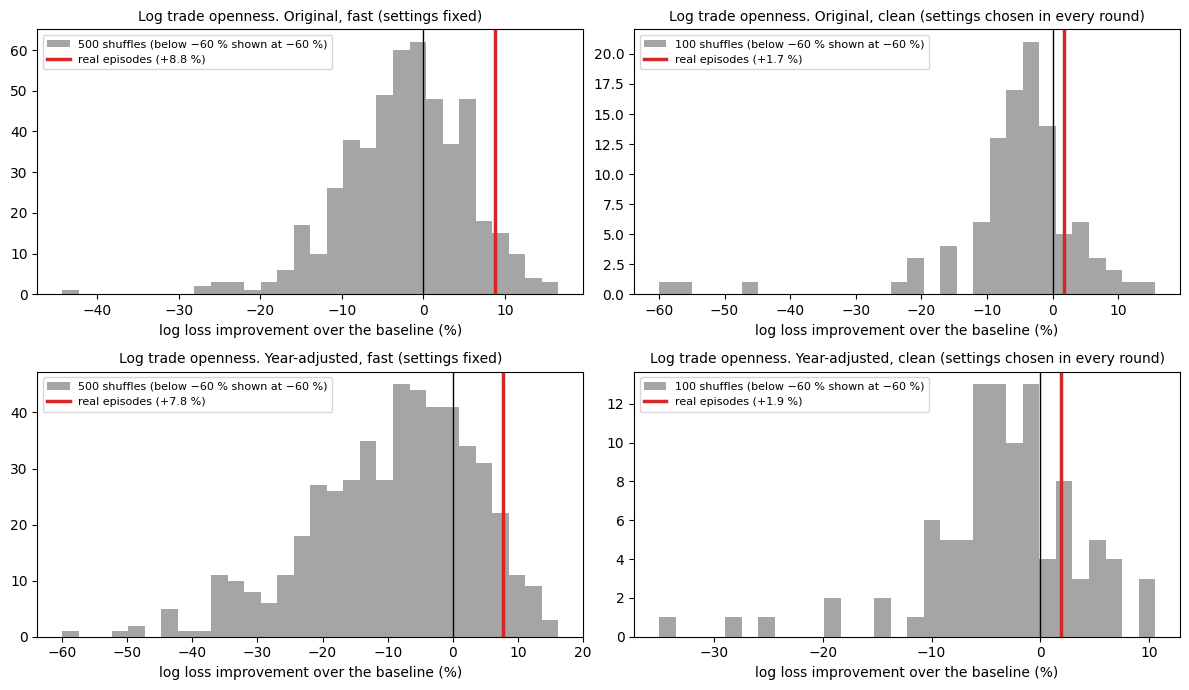

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, ((t, version), (real, fake)) in zip(axes.ravel(), placebo_log.items()):
    ax.hist(np.clip(fake[:, 0], -60, None), bins=30, color="tab:grey", alpha=0.7, label=f"{len(fake)} shuffles (below −60 % shown at −60 %)")
    ax.axvline(real[0], color="tab:red", lw=2.5, label=f"real episodes ({real[0]:+.1f} %)")
    ax.axvline(0, color="black", lw=1)
    ax.set_title(f"Log trade openness. {t}, {version}", fontsize=10); ax.set_xlabel("log loss improvement over the baseline (%)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# Learning log, Session 5

## Part A: evaluating models (10 Nov 2026)

**Course:** Machine Learning Specialization, Course 2 Week 3, Parts A–B (training / cross-validation / test sets, model selection, bias and variance, baseline level of performance, learning curves)

**Question:** Sessions 3 and 4 never beat the simple guess. Is that because the models are too simple (high bias), too flexible for so little data (high variance), or because the inputs hold almost no information about what comes next? And would more data help?

**Setup, decided before fitting:**
- Same rows, inputs and targets as Sessions 3–4: 96 consolidation episodes in 24 countries; ΔCAPB and the four lagged controls; inflation capped at ±30 %; original and year-adjusted "weak growth" targets with cut-offs from the training countries only.
- Model family: logistic regression on polynomial features of the five inputs (degree 1, 2 or 3 → 5, 20 or 55 features), z-scored on the training countries only, λ from 0.01 to 1000 (C = 1/λ).
- J_train and J_cv are log loss without the λ term. The baseline level of performance is the simple guess (the training share of "weak").
- Cross-validation: the 20 training countries in 4 groups (15 to 20 episodes each). Each fold trains on about 53 episodes and scores only its left-out group.

**Train / cross-validation / test in this project**
- Training set: the countries a model learns from. Cross-validation set: training countries held back to choose the degree and λ. Test set: the six hidden countries (Belgium, Greece, Lithuania, Malta, Slovakia, Spain).
- The test set should be used once. Ours has been read in every session since Session 1, so it is no longer fully clean, even though nothing was tuned on it on purpose (apart from the Session 3 leak, since fixed). That is why "every country hidden in turn" and the 500 random splits matter more.

**J_train and J_cv against λ (cross-validation on the 20 training countries)**

| λ | Original, degree 1: J_train / J_cv | Original, degree 2 | Original, degree 3 | Year-adjusted, degree 1 | Year-adjusted, degree 2 | Year-adjusted, degree 3 |
|---|---|---|---|---|---|---|
| 0.01 | 0.617 / 0.877 | 0.338 / 2.486 | 0.116 / 2.881 | 0.629 / 0.901 | 0.379 / 2.047 | 0.125 / 2.887 |
| 1 | 0.619 / 0.823 | 0.459 / 1.077 | 0.372 / 1.201 | 0.631 / 0.860 | 0.482 / 0.898 | 0.377 / 1.365 |
| 10 | 0.640 / 0.732 | 0.560 / 0.760 | 0.504 / 0.787 | 0.646 / 0.764 | 0.563 / 0.660 | 0.504 / 0.926 |
| 30 | 0.659 / 0.706 | 0.607 / 0.696 | 0.565 / 0.682 | 0.663 / 0.722 | 0.608 / **0.643** | 0.564 / 0.763 |
| 100 | 0.676 / 0.698 | 0.649 / **0.680** | 0.618 / 0.702 | 0.678 / 0.703 | 0.649 / 0.658 | 0.619 / 0.750 |
| 1000 | 0.687 / 0.698 | 0.683 / 0.694 | 0.675 / 0.697 | 0.688 / 0.697 | 0.684 / 0.690 | 0.676 / 0.701 |
| Simple guess | J_cv 0.698 | | | J_cv 0.696 | | |

- **The textbook picture.** With little regularization, J_train is low and J_cv is far above it: **high variance**. Degree 3 with λ = 0.01 fits the training countries almost perfectly (J_train 0.12) and is terrible on the cross-validation countries (J_cv 2.9). With a lot of regularization, J_train and J_cv both rise or fall to the simple guess.
- **Degree 1 (the Session 3 model) never gets below the guess** in cross-validation: its best J_cv is 0.698 at λ = 100–1000, the same as the guess.
- **Degree 2 dips below the guess:** J_cv 0.680 vs 0.698 (original, λ = 100) and 0.643 vs 0.696 (year-adjusted, λ = 30). Cross-validation picks these. But the lowest J_cv among 27 options scored on the same 4 groups is optimistic: that is the course's reason for a separate test set.

**Learning curves (train on 2 to 16 training countries, score 4 others, 200 repeats)**

| At 16 training countries (about 57 episodes) | J_train | J_cv | Simple guess |
|---|---|---|---|
| Original, chosen by cross-validation (degree 2, λ = 100) | 0.650 | 0.695 | 0.694 |
| Original, flexible (degree 3, λ = 0.1) | 0.255 | 3.18 | 0.694 |
| Year-adjusted, chosen (degree 2, λ = 30) | 0.598 | 0.714 | 0.694 |
| Year-adjusted, flexible (degree 3, λ = 0.1) | 0.243 | 2.76 | 0.694 |

- **The chosen models:** J_cv falls and J_train rises as countries are added, and they close in on the simple guess from both sides. More data makes them *as good as* the guess, not better.
- **The flexible models:** a huge, slowly closing gap (high variance). More data would help them, but they start so far above the guess that 26 EU countries could never be enough.
- **Diagnosis:** in course terms, the well-regularized models have no variance problem, and their J_train is only a little below the guess. If the best achievable performance were much better than the guess, that would be high bias, and a more flexible model would fix it. But the more flexible models (degree 3 here, the network in Session 4) do not help. The limit is most likely the information in the data: these inputs say little about TFP growth over the next years. More countries do not exist; more years would help only slowly.

**The test, once: the cross-validation choice through the three tests**

| Test | Original (degree 2, λ = 100) | Year-adjusted (degree 2, λ = 30) |
|---|---|---|
| Six hidden: log loss vs baseline | 0.667 vs 0.710 | 0.624 vs 0.718 |
| Six hidden: accuracy vs baseline | 52 % vs 40 % | 52 % vs 40 % |
| Each hidden in turn: log loss vs baseline | 0.919 vs 0.694 (−32.4 %) | 0.704 vs 0.700 (−0.6 %) |
| Each hidden in turn: accuracy vs baseline | 58.3 % vs 49.0 % | 60.4 % vs 42.7 % |
| Countries won | 15 of 24 | 14 of 24 |
| 500 random splits: log loss better | 77 % (median +2.9 %) | 69 % (median +3.5 %) |
| Settings chosen across the 24 rounds | (2, 30) ×13, (2, 10) ×8, (1, 300), (2, 100), (3, 10) | (2, 30) ×11, (2, 10) ×5, (2, 100) ×5, (2, 300), (1, 10), (1, 300) |

- **Luxembourg again.** With the original target, Luxembourg's round chose degree 3 with λ = 10 and scored a log loss of 5.91 against 0.674 for the guess: that one round costs 39.3 points, more than the whole −32.4 %. With the year-adjusted target its round chose degree 1 with λ = 10 (1.313 vs 0.691, −4.6 points). The next worst rounds (Hungary, Estonia, Spain) cost less than 1 point each.
- Without Luxembourg's round the overall result would be roughly +7 % (original) and +4 % (year-adjusted). Together with 69–77 % of random splits, this is the most frequent small gain so far. But one unstable tuning round still decides the sign, the gain is small, the 500 splits use the setting chosen once (slightly optimistic), and no placebo check has been run on degree 2. A lead to check, not a usable predictor.

**Placebo test for the degree-2 model (added 10 Nov 2026)**
- Within each country, the ΔCAPB values were shuffled across years, so each country keeps its number of episodes and their sizes but *which years* count as consolidations becomes random. The model was rerun on each shuffled panel with every country hidden in turn.
- Fast version: 500 shuffles, settings fixed at the section 3 choice (degree 2; λ = 100 / 30). Slightly optimistic and may favour the real episodes, as in Session 3. Clean version: 100 shuffles, degree and λ chosen again by cross-validation inside every round, so nothing is tuned on the real episodes.

| | Original, fast | Original, clean | Year-adjusted, fast | Year-adjusted, clean |
|---|---|---|---|---|
| Shuffles | 500 | 100 | 500 | 100 |
| Real: log loss vs baseline | +4.1 % | −32.4 % | +5.6 % | −0.6 % |
| Shuffled: median (middle 90 %) | +0.4 % (−6.4 to +6.2) | −6.5 % (−40.0 to +5.2) | −3.5 % (−19.5 to +7.9) | −7.6 % (−29.4 to +4.1) |
| Shuffles at least as good (log loss) | 15 % | 94 % | 10 % | 15 % |
| Real: accuracy minus baseline | +11.5 points | +9.4 | +16.7 | +17.7 |
| Shuffled accuracy: median (middle 90 %) | +3.1 (−3.1 to +18.7) | +1.0 (−4.2 to +18.8) | +5.2 (−2.1 to +18.8) | +1.0 (−2.1 to +13.6) |
| Shuffles at least as good (accuracy) | 12 % | 9 % | 6 % | **2 %** |
| Countries won: real vs shuffled median | 16 vs 14 | 15 vs 14 | 13 vs 14 | 14 vs 14 |

- **On log loss, the real episodes are not unusual** in any version: 10–15 % of shuffles do at least as well, and with the original target and tuning in every round, 94 % do (the real result is worse than most shuffles, because of Luxembourg's round). The small degree-2 gain is not specific to the consolidation years.
- **On accuracy, one version stands out:** with the year-adjusted target and tuning in every round, only 2 % of shuffles get as many yes/no calls right. The other versions are 6–12 %. This matches the Session 3 placebo (2–3 % on accuracy, not unusual on log loss): a faint pattern in which side of 50 % the predictions fall, tied to the real years, but not in how confident they are. With 8 comparisons, one 2 % is weak evidence.
- **Unstable tuning is general, not only Luxembourg:** the shuffled panels with tuning in every round have a median of −6.5 % and −7.6 %, and some fall below −40 %. When the best setting has to be chosen on about 50 episodes, a badly wrong round is common.
- **Conclusion:** the degree-2 lead does not survive the placebo on log loss. Still no usable predictor.

**Why Luxembourg goes wrong (checked 10 Nov):** its trade openness in the five episodes is 240 to 376 % of GDP (z-scores 1.9 to 4.0 among the 96 episodes); the median episode is 109 %, and the next most open countries average 150 to 207 % (Hungary, Malta, Ireland). When Luxembourg is hidden, the model has to extrapolate far outside what it was trained on, and squared or cubed terms make that extreme. The thesis does not have this problem because country fixed effects absorb each country's usual openness. Dropping Luxembourg would choose the sample by the result; a rule for all countries (log of trade openness, or capping inputs at the training range when predicting) is the better fix, decided before rerunning.

**A rule for every country: the log of trade openness (added 10 Nov 2026)**
- Decided before running: use the natural log of trade openness for every country; nothing else changes (same degrees, λ values, cross-validation groups, targets and tests). Luxembourg stays in. Its episodes' z-scores fall from 1.9–4.0 to 1.7–2.7.

| Test | Original, raw | Original, log | Year-adjusted, raw | Year-adjusted, log |
|---|---|---|---|---|
| Chosen on the training countries (degree, λ) | (2, 100) | (2, 30) | (2, 30) | (2, 10) |
| Lowest J_cv vs simple guess | 0.680 vs 0.698 | 0.674 vs 0.698 | 0.643 vs 0.696 | 0.614 vs 0.696 |
| Six hidden: log loss vs baseline | 0.667 vs 0.710 | 0.620 vs 0.710 | 0.624 vs 0.718 | 0.594 vs 0.718 |
| Six hidden: accuracy vs baseline | 52 % vs 40 % | 72 % vs 40 % | 52 % vs 40 % | 60 % vs 40 % |
| Each hidden in turn: log loss vs baseline | 0.919 vs 0.694 (−32.4 %) | **0.682 vs 0.694 (+1.7 %)** | 0.704 vs 0.700 (−0.6 %) | **0.686 vs 0.700 (+1.9 %)** |
| Each hidden in turn: accuracy vs baseline | 58.3 % vs 49.0 % | 62.5 % vs 49.0 % | 60.4 % vs 42.7 % | 61.5 % vs 42.7 % |
| Countries won | 15 of 24 | 16 of 24 | 14 of 24 | 13 of 24 |
| 500 random splits: log loss better | 77 % (median +2.9 %) | **84 % (median +6.8 %)** | 69 % (median +3.5 %) | 64 % (median +3.3 %) |
| Luxembourg's round (effect on overall) | −39.3 points | −6.6 points | −4.6 points | −3.0 points |

- **The rule fixes most of the Luxembourg problem.** Its round still goes worst (log loss 1.554 vs 0.674 on the original target), but costs 6.6 points instead of 39.3. Tuning is also steadier: degree 2 is chosen in 22 of 24 rounds on the original target.
- **For the first time a model beats the simple guess in all three tests**, on both targets: +1.7 % and +1.9 % with every country hidden in turn, and better in 84 % and 64 % of random splits.
- **But read it carefully.**
  - The gain is small: about 2 % in log loss with every country hidden in turn, and the year-adjusted model wins only 13 of 24 countries.
  - The rule is principled and was fixed before running, but it was chosen *after* seeing Luxembourg's problem, and across Sessions 3–5 many versions have been tried. Among that many tries, one small positive result can appear by chance.
  - The placebo above was run on raw trade openness, where the gain was not unusual. It has not been run on this version, so there is no evidence yet that the gain is about consolidations rather than about the controls predicting TFP growth in general.
- **Conclusion:** a small, promising result, not yet a finding. The next check is the placebo on the log version.

**Placebo test on the log version (added 10 Nov 2026)**
- The same two versions as for raw trade openness: 500 shuffles with the settings fixed at the section 7 choice (slightly optimistic, may favour the real episodes), and 100 shuffles with degree and λ chosen again in every round (no such caveat).

| | Original, fast | Original, clean | Year-adjusted, fast | Year-adjusted, clean |
|---|---|---|---|---|
| Shuffles | 500 | 100 | 500 | 100 |
| Real: log loss vs baseline | +8.8 % | +1.7 % | +7.8 % | +1.9 % |
| Shuffled: median (middle 90 %) | −1.9 % (−15.5 to +8.8) | −3.8 % (−20.8 to +6.2) | −7.1 % (−33.9 to +8.3) | −3.2 % (−14.9 to +6.9) |
| Shuffles at least as good (log loss) | 5 % | 16 % | 6 % | 21 % |
| Real: accuracy minus baseline | +16.7 points | +13.5 | +19.8 | +18.8 |
| Shuffles at least as good (accuracy) | 8 % | 9 % | 5 % | **2 %** |
| Countries won: real vs shuffled median | 16 vs 13 | 16 vs 14 | 12 vs 13 | 13 vs 14 |

- **The clean version decides it:** with the settings chosen in every round, 16 % and 21 % of shuffled panels do at least as well on log loss. The small gain is not unusual, so it mostly comes from the controls predicting TFP growth in general, not from which years were consolidations.
- The fast version looks better (5–6 % of shuffles as good), but its settings were tuned on the real episodes, which favours them. That gap is exactly why the clean version is the one to trust.
- **The same accuracy pattern for the third time:** with the year-adjusted target and tuning in every round, only 2 % of shuffles get as many yes/no calls right (Session 3 placebo: 2–3 %; raw trade openness above: 2 %). It is one faint pattern seen three times on the same data, not three independent confirmations, and it shows up in which side of 50 % the predictions fall, not in how confident they are.
- **Conclusion:** the log rule fixes the Luxembourg problem and gives the first model that beats the guess in all three tests, but the placebo shows the gain is not about consolidations. Still no usable predictor of which consolidations are followed by weak growth.

**Main lessons**
- J_train and J_cv together show what a single score cannot: low J_train with high J_cv is overfitting; both stuck at the guess means nothing is being learned.
- The J_cv of the chosen model is optimistic, because it won a contest on the same folds (0.643 in cross-validation, 0.704 with every country hidden in turn).
- Learning curves answer "would more data help?". Here the regularized models meet at the guess, and the flexible ones would need far more countries than the EU has.
- A test set read in every session slowly stops being a test set.
- Unstable tuning is the weak point: in Sessions 3, 4 and 5 the worst round is Luxembourg, where tuning picks a less regularized model and is badly wrong.

- A placebo is what turns "it beats the guess" into "it beats the guess *because of the consolidations*". Here the first win in all three tests did not pass it.
- A placebo with tuning inside every round needs no caveat; it costs time (here 100 shuffles in parallel, about 10 minutes), but it is the clean version.

- Fix an outlier's problem with a rule for every country, not by dropping the country. Here the log of trade openness turned −32.4 % into +1.7 %.

**Next:** Part B after Course 2 Week 4: decision trees, to test whether there is a large-consolidation threshold, using the log of trade openness and the clean placebo from the start.